# Chronos zero-shot: 재현 가능한 기준 실험

**02 갈무리:** zero-shot 기준선은 확보했습니다. 고정한 XPU 실행의 macro 중앙값 RMSE는 **0.016307**, 평균 예측 RMSE는 **0.018540**입니다. 마지막 절에서 저장된 진단 CSV로 기준 지표를 확인합니다. 04에서는 같은 실행 환경과 평가 조건으로 이 기준선을 다시 맞춥니다.

MAT의 방전 용량으로 `SOH = Qk / Q1`을 구성합니다. 실제 최근 64개 SOH를 사용해 다음 16개를 예측하는 **rolling-origin** 실험입니다. 매 시점의 실제 관측을 새로 제공하므로 첫 64개만 이용하는 수명 전체 예측과는 다릅니다.

모델 revision, 데이터 해시, 라이브러리 버전, seed와 예측 배열을 실행별로 저장합니다. 기본 설정은 100 samples, 추론 seed 42/43/44이며 점 예측은 보간 중앙값과 sample mean을 함께 보고합니다. `configs/experiment.json`에서 설정을 변경하세요.

R²는 배터리·seed별 전체 window/horizon을 펼쳐 `1 - SSE/SST`로 계산한 뒤 배터리를 동일 가중치로 평균합니다. 1은 완벽한 예측, 0은 평가 target 평균을 항상 예측한 수준이며 음수도 가능합니다. Horizon/개별 window 점수는 해당 범위의 평균을 기준으로 합니다. 상수 target은 NaN입니다. 원본 실행 기록은 보존하고 R²를 포함한 파생 평가를 `results/evaluation_r2/`에 저장합니다.

이전 노트북은 Git 이력에 보관했습니다. 20-sample 실험의 결과는 `results/metrics/`에서 확인할 수 있습니다.

In [1]:
from pathlib import Path
import sys

# Works with the kernel started from the project root or notebooks/.
PROJECT_ROOT = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / "data" / "raw").is_dir() and (p / "src" / "soh_experiment.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.soh_experiment import (
    load_config, load_soh, make_windows, temporal_split,
    find_zeroshot, find_lobo, run_zeroshot, run_lobo, verify_saved_run,
)
from src.soh_plots import forecast_grid, horizon_comparison, validation_curves, window_comparison
from src.soh_evaluation import export_run, export_diagnosis, evaluation_directory

CONFIG = load_config(PROJECT_ROOT)
FORCE_RERUN = False  # True: new run directory; False: reuse only verified compatible artifacts.
print("Project:", PROJECT_ROOT)
print(CONFIG)


Project: C:\Users\dbsgh\Desktop\Lab\chronos-battery-soh
ExperimentConfig(model_id='amazon/chronos-t5-base', revision='ad294eaacead15db499b740ea4122266dd2a81a2', battery_ids=('B0005', 'B0006', 'B0007', 'B0018'), context_length=64, prediction_length=16, device='auto', inference_batch_size=16, num_samples=100, inference_seeds=(42, 43, 44), temperature=1.0, top_k=50, top_p=1.0, train_seeds=(42,), batch_size=16, learning_rate=0.0001, weight_decay=0.0, lora_rank=8, lora_alpha=16, lora_dropout=0.05, max_epochs=10, validation_fraction=0.2, validation_samples=32, validation_seed=31415, patience=3, min_delta=1e-05)


## 원본 데이터 및 평가 윈도우
정규화에는 첫 관측만 사용합니다. 배터리별 오차를 동일 가중치로 평균합니다.

In [2]:
soh_data = load_soh(PROJECT_ROOT, CONFIG)
display(pd.DataFrame([
    {"battery": b, "cycles": len(s), "first_soh": s[0], "last_soh": s[-1],
     "evaluation_windows": len(make_windows(s, CONFIG.context_length, CONFIG.prediction_length)["target"])}
    for b, s in soh_data.items()
]))

,battery,cycles,first_soh,last_soh,evaluation_windows
0,B0005,168,1.0,0.713756,89
1,B0006,168,1.0,0.582545,89
2,B0007,168,1.0,0.757491,89
3,B0018,132,1.0,0.722937,53


## 추론 및 저장
동일한 코드·데이터·모델·환경·추론 설정의 완료된 실행만 재사용합니다. 중단되거나 손상된 결과는 재사용하지 않습니다.

In [3]:
ZERO_RUN = None if FORCE_RERUN else find_zeroshot(PROJECT_ROOT, CONFIG)
ZERO_RUN = ZERO_RUN or run_zeroshot(PROJECT_ROOT, CONFIG)
print("Saved run:", ZERO_RUN)
display(verify_saved_run(ZERO_RUN, PROJECT_ROOT, CONFIG))
ZERO_EVAL = export_run(PROJECT_ROOT, ZERO_RUN)

Saved run: C:\Users\dbsgh\Desktop\Lab\chronos-battery-soh\results\runs\20260923T063348Z_zeroshot_b57856


{'run_id': '20260923T063348Z_zeroshot_b57856',
 'metric_rows_verified': 32,
 'artifacts_verified': 17,
 'status': 'passed'}

## 자동 계산된 성능
표준편차는 추론 seed별 점수 변동입니다. 중첩 윈도우를 독립 표본으로 간주한 신뢰구간이 아닙니다. 단일 기준 모델의 표준편차는 정의되지 않아 NaN으로 표시합니다.

In [4]:
summary = pd.read_csv(ZERO_EVAL / "summary.csv")
metrics = pd.read_csv(ZERO_EVAL / "metrics.csv")
display(summary)
display(metrics.groupby(["model", "estimator", "battery"])[["rmse", "mae", "r2"]].mean())
display(metrics[metrics.model == "ZeroShot"].groupby("battery")[["coverage80", "width80"]].mean())

,model,estimator,rmse_mean,rmse_std,mae_mean,mae_std,n_runs,r2_mean,r2_std,r2_n_runs
0,LastValue,median,0.021749,NaN,0.017814,NaN,1,0.577698,NaN,1
1,Linear,median,0.022994,NaN,0.017579,NaN,1,0.396081,NaN,1
2,ZeroShot,mean,0.018540,0.001475,0.012373,0.000447,3,0.616669,0.072289,3
3,ZeroShot,median,0.016307,0.000155,0.011607,0.000044,3,0.676844,0.006572,3


rmse       mae        r2
model     estimator battery                              
LastValue median    B0005    0.022004  0.018166  0.809632
                    B0006    0.024485  0.019867  0.740529
                    B0007    0.017806  0.014452  0.781682
                    B0018    0.022700  0.018771 -0.021051
Linear    median    B0005    0.019174  0.015175  0.855449
                    B0006    0.026631  0.019419  0.693066
                    B0007    0.016162  0.013084  0.820126
                    B0018    0.030008  0.022639 -0.784318
ZeroShot  mean      B0005    0.013980  0.009507  0.923080
                    B0006    0.020228  0.013585  0.822900
                    B0007    0.016665  0.009406  0.800628
                    B0018    0.023288  0.016995 -0.079932
          median    B0005    0.012601  0.009050  0.937543
                    B0006    0.018900  0.012889  0.845382
                    B0007    0.011423  0.007927  0.910154
                    B0018    0.022303  0.016563  0.014299

,coverage80,width80
battery,,
B0005,0.812968,0.034216
B0006,0.766386,0.043659
B0007,0.807116,0.029546
B0018,0.826258,0.062221


## 예측 구간과 horizon별 오차
아래 예시는 첫 번째 추론 seed의 첫·중간·마지막 윈도우입니다. 10~90% 예측 구간은 실제 coverage를 함께 확인해야 합니다.

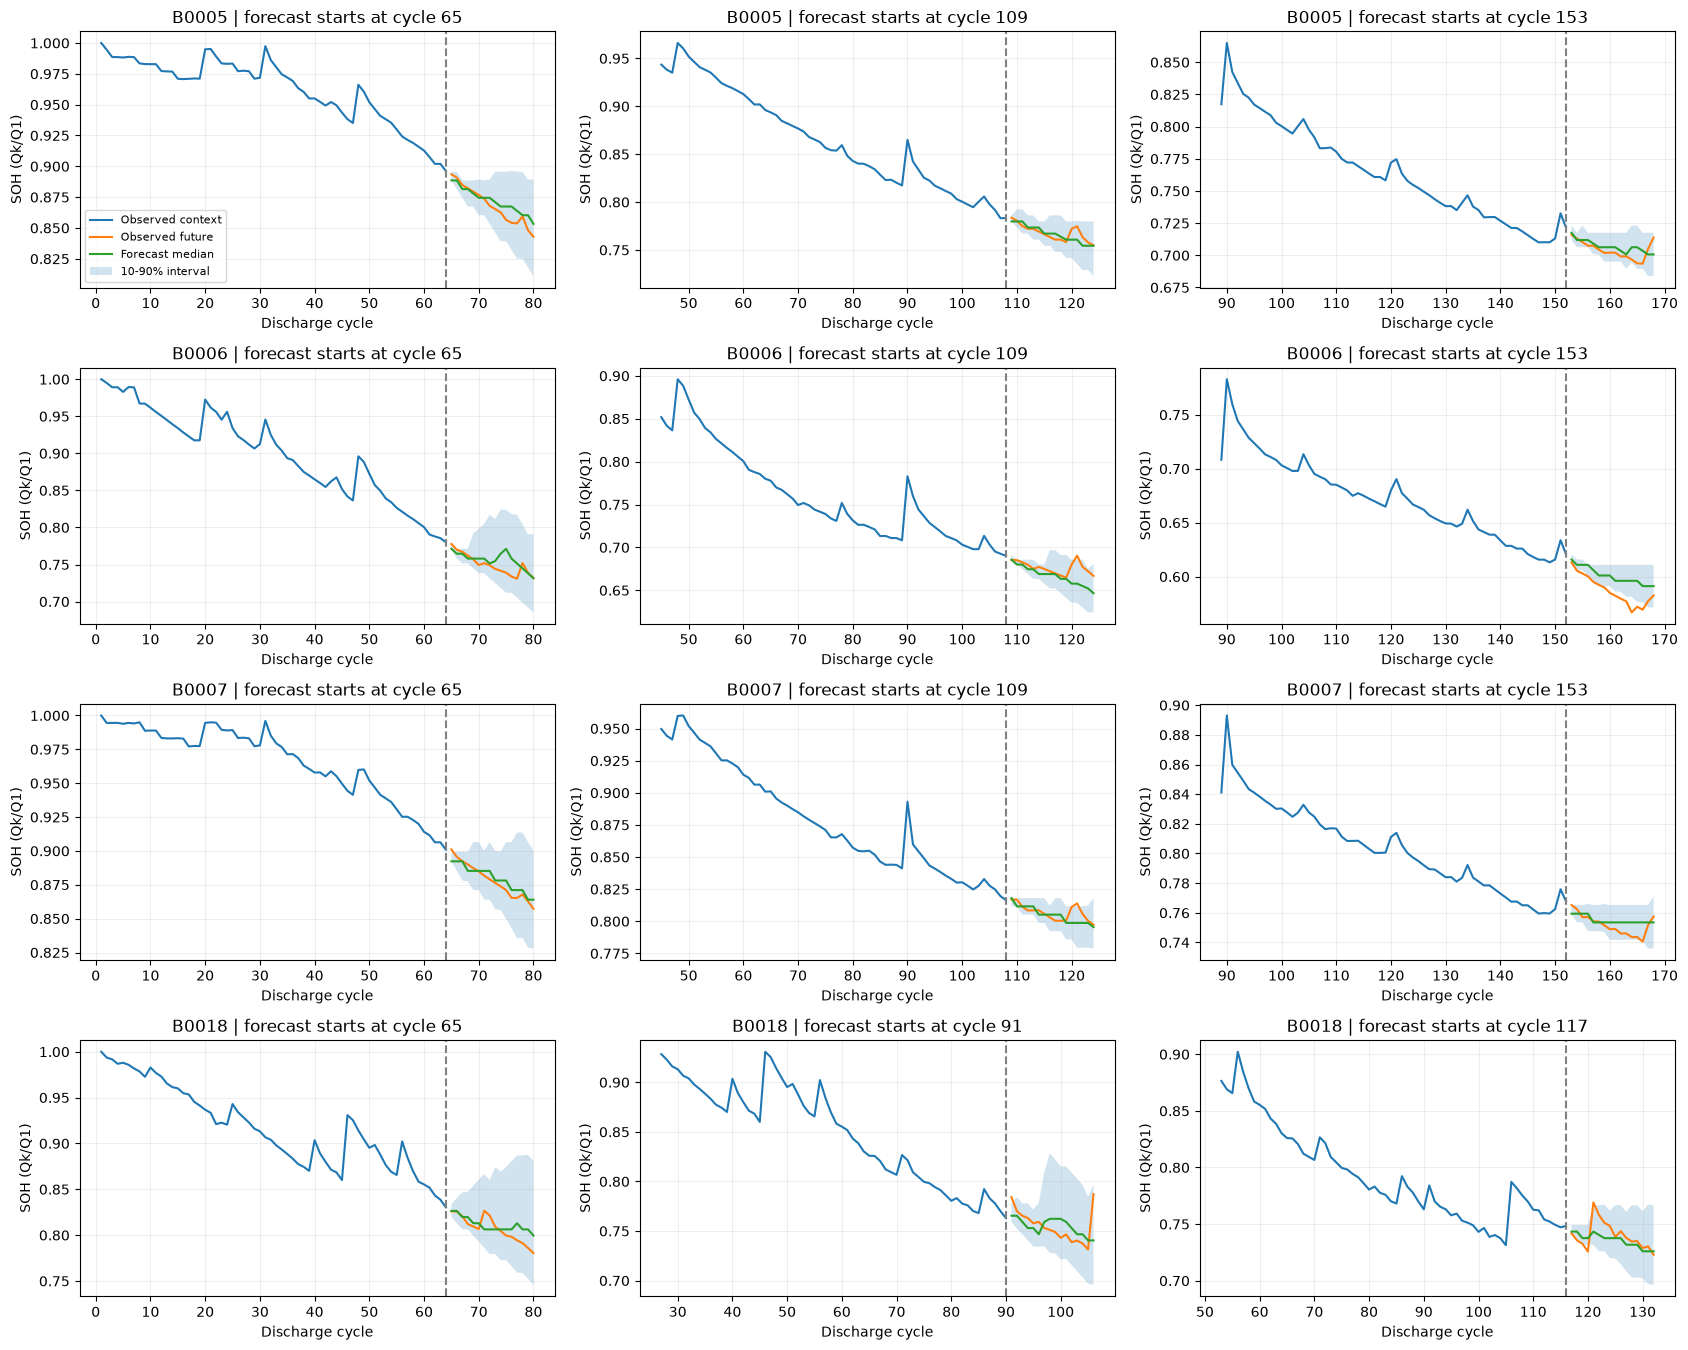

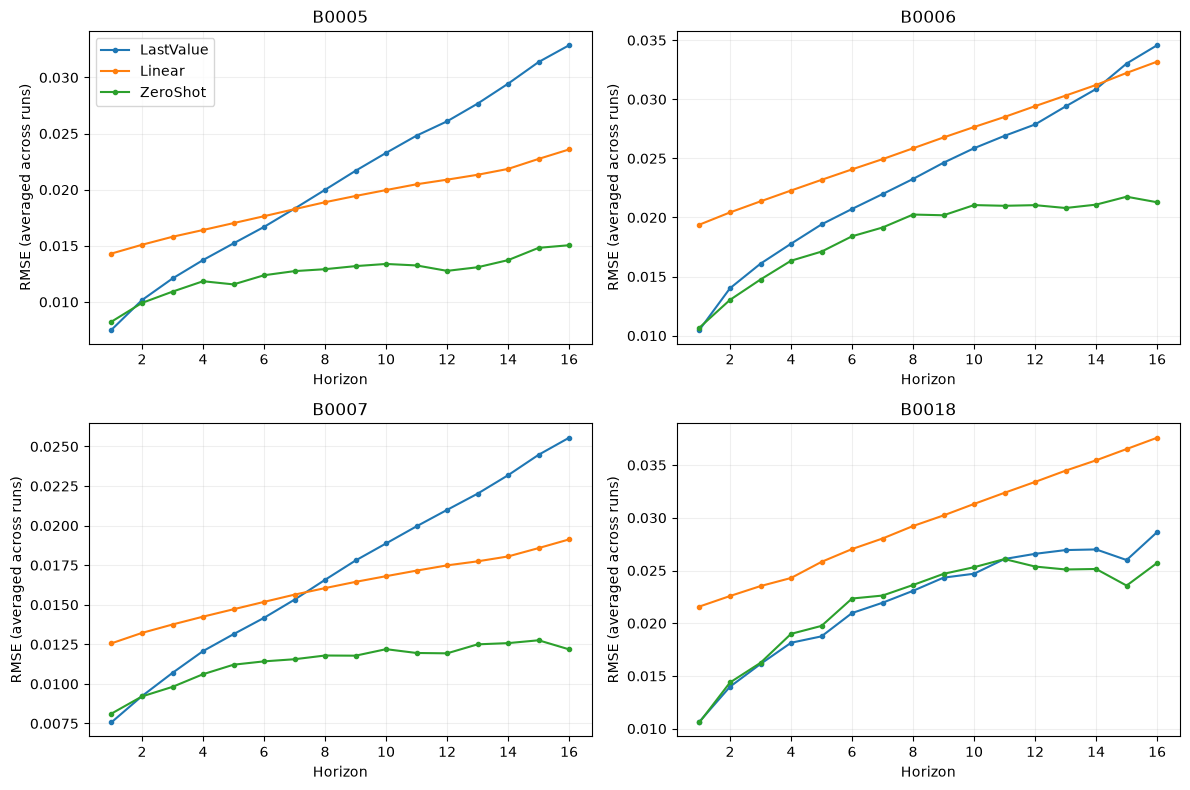

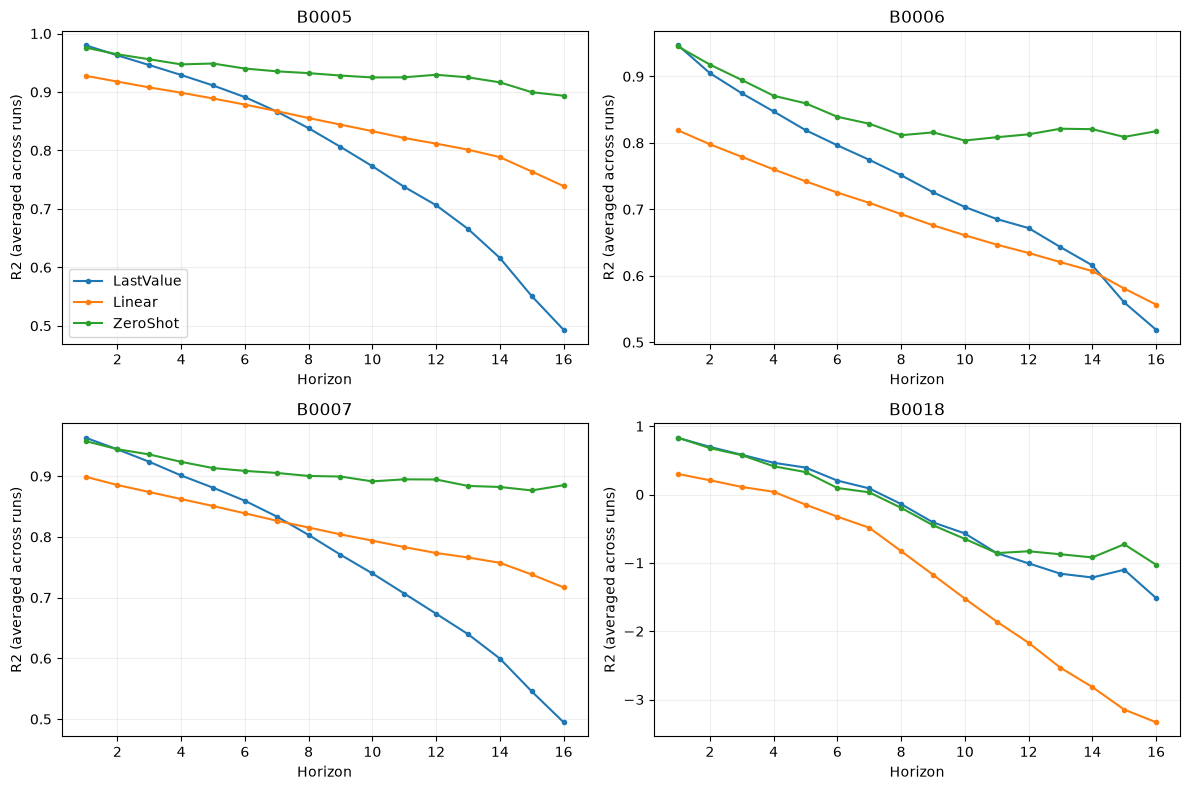

In [5]:
forecast_grid(ZERO_RUN)
plt.show()
horizon_comparison(ZERO_RUN)
plt.show()
horizon_comparison(ZERO_EVAL, metric="r2")
plt.show()

## 해석 시 주의

- 한 실제 cycle이 최대 16개 평가 윈도우에 포함됩니다. 배터리 수는 4개입니다.
- `sqrt(mean(error²))`와 window별 RMSE의 평균은 서로 다릅니다.
- Chronos T5의 토큰 양자화 때문에 샘플 예측이 계단 형태일 수 있습니다. 보간 중앙값은 두 bin 사이 값을 반환할 수도 있습니다.
- 03 노트북은 이 실행과 호환되는 zero-shot 예측을 찾아 같은 target, horizon, 집계 규칙으로 LoRA와 비교합니다.

## 02 갈무리: 04에 넘길 zero-shot 기준선

아래 표는 `20260923T063348Z_zeroshot_b57856`의 고정 결과입니다. 위 실행 셀에서 다른 설정으로 새 실험을 만들더라도 이 표는 바뀌지 않습니다. 추론 seed 42/43/44의 점수를 평균하고 네 배터리에 같은 가중치를 줍니다. `mean_rmse`는 100개 sample을 평균한 예측의 오차이며, 배터리 평균이라는 뜻이 아닙니다. CRPS는 예측 분포 점수로 낮을수록 좋습니다.

결론은 **기준선 확보**입니다. zero-shot에도 드문 극단 sample이 있고, 80% 구간의 실제 포함률은 전체 평균 약 80.32%입니다. 이 데이터에서 평가한 미래 16-cycle 예측과 장기 수명/RUL 예측을 구분합니다.

In [6]:
DIAGNOSIS = PROJECT_ROOT / "results" / "diagnostics" / "20260929"
DIAGNOSIS_EVAL = export_diagnosis(PROJECT_ROOT, DIAGNOSIS)
diagnostic_metrics = pd.read_csv(DIAGNOSIS_EVAL / "seed_confirmation" / "metrics.csv")
keys = ["model", "battery", "inference_seed"]
assert len(diagnostic_metrics) == 36 and not diagnostic_metrics.duplicated(keys).any()
assert set(diagnostic_metrics["inference_seed"]) == {42, 43, 44}
score_columns = ["median_rmse", "median_r2", "mean_rmse", "mean_r2", "crps", "above2_rate", "coverage80"]
# First average inference seeds, then give the four batteries equal weight.
diagnostic_battery = diagnostic_metrics.groupby(["model", "battery"])[score_columns].mean()
diagnostic_macro = diagnostic_battery.groupby(level="model").mean()
print("Fixed snapshot: 20260929; original XPU runs + EOS-loss ablation; training seed 42")
display(diagnostic_macro.loc[["zero"]].round(6))
display(diagnostic_battery.xs("zero", level="model").round(6))

Fixed snapshot: 20260929; original XPU runs + EOS-loss ablation; training seed 42


,median_rmse,median_r2,mean_rmse,mean_r2,crps,above2_rate,coverage80
model,,,,,,,
zero,0.016307,0.676844,0.01854,0.616669,0.008769,0.000063,0.803182


,median_rmse,median_r2,mean_rmse,mean_r2,crps,above2_rate,coverage80
battery,,,,,,,
B0005,0.012601,0.937543,0.013980,0.923080,0.006828,0.000054,0.812968
B0006,0.018900,0.845382,0.020228,0.822900,0.009832,0.000023,0.766386
B0007,0.011423,0.910154,0.016665,0.800628,0.005939,0.000105,0.807116
B0018,0.022303,0.014299,0.023288,-0.079932,0.012478,0.000071,0.826258


02에서는 추가 튜닝 없이 이 결과를 기준선으로 보관합니다. 03은 LoRA의 학습 효과와 분포 악화를 다룹니다. 04 Full fine-tuning은 별도 실험이며 아직 실행하지 않았습니다.

[02·03 정리와 04 비교 조건](../docs/02_03_closeout.md) · [상세 진단 보고서](../results/diagnostics/20260929/diagnosis.md)